In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [3]:
df = pd.read_csv("../Data/raw/telco.csv")

print(df.shape)

(7043, 50)


In [4]:
columns_to_drop = [
    "Customer ID",
    "City",
    "Zip Code",
    "Country",
    "State",
    "Latitude",
    "Longitude",
    "Quarter",
    "Churn Category",
    "Churn Reason",
    "Churn Score",
    "Customer Status"
]

df = df.drop(columns=columns_to_drop)

print(df.shape)

(7043, 38)


In [5]:
X = df.drop(columns=["Churn Label"])
y = df["Churn Label"]

print("X:", X.shape)
print("y:", y.shape)

X: (7043, 37)
y: (7043,)


In [6]:
categorical_features = X.select_dtypes(include="str").columns.tolist()
numerical_features = X.select_dtypes(exclude="str").columns.tolist()

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nCategorical:")
print(categorical_features)

print("\nNumerical:")
print(numerical_features)

Categorical features: 22
Numerical features: 15

Categorical:
['Gender', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Referred a Friend', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method']

Numerical:
['Age', 'Number of Dependents', 'Population', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'Satisfaction Score', 'CLTV']


In [7]:
from sklearn.preprocessing import StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical",
         OneHotEncoder(handle_unknown="ignore", drop="first"),
         categorical_features),

        ("numerical",
         StandardScaler(),
         numerical_features)
    ]
)

In [8]:
model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ]
)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data :", X_test.shape)

Training data: (5634, 37)
Testing data : (1409, 37)


In [10]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Gender','Age','Under 30',...,'Total Revenue','Satisfaction Score','CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [11]:
y_pred = model.predict(X_test)

print(y_pred[:20])

['No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'No' 'No' 'No']


In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9602555003548616


In [13]:
train_accuracy = model.score(X_train, y_train)
test_accuracy = model.score(X_test, y_test)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.963258785942492
Testing Accuracy: 0.9602555003548616


In [14]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.96      0.98      0.97      1035
         Yes       0.95      0.89      0.92       374

    accuracy                           0.96      1409
   macro avg       0.96      0.94      0.95      1409
weighted avg       0.96      0.96      0.96      1409



[[1019   16]
 [  40  334]]


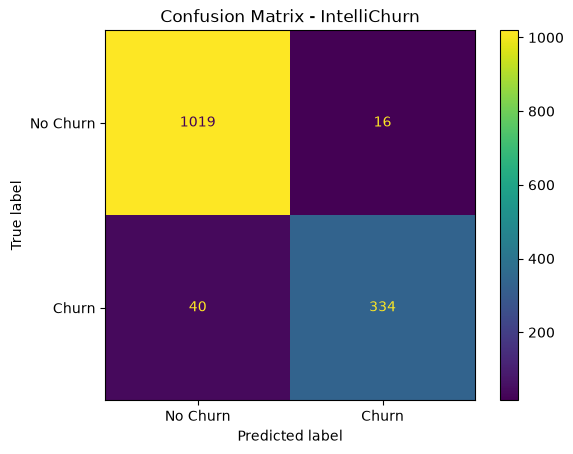

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()
plt.title("Confusion Matrix - IntelliChurn")
plt.show()

SECOND MODEL USING RANDOM FOREST 

In [16]:
from sklearn.ensemble import RandomForestClassifier

In [17]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ))
    ]
)

In [18]:
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](37,)","['Gender','Age','Under 30',...,'Total Revenue','Satisfaction Score','CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,37
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``

In [19]:
rf_pred = rf_model.predict(X_test)

print(rf_pred[:20])

['No' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No' 'Yes' 'No' 'No' 'No' 'Yes'
 'No' 'No' 'No' 'No' 'No' 'No']


In [20]:
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9552874378992193


In [21]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

          No       0.95      0.99      0.97      1035
         Yes       0.97      0.86      0.91       374

    accuracy                           0.96      1409
   macro avg       0.96      0.92      0.94      1409
weighted avg       0.96      0.96      0.95      1409



[[1026    9]
 [  54  320]]


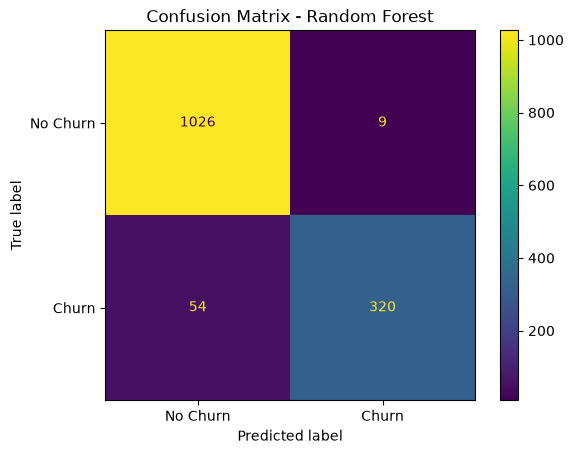

In [22]:
rf_cm = confusion_matrix(y_test, rf_pred)

print(rf_cm)

rf_disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Churn", "Churn"]
)

rf_disp.plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

## Model Comparison

Two machine learning models were evaluated for IntelliChurn:

1. Logistic Regression
2. Random Forest

Logistic Regression achieved a test accuracy of 96.03%, with 95% precision,
89% recall, and 92% F1-score for churned customers.

Random Forest achieved a test accuracy of 95.53%, with 97% precision,
86% recall, and 91% F1-score for churned customers.

Since the primary objective of IntelliChurn is to identify customers
who are likely to churn, recall is an important business metric.

Logistic Regression identified more actual churners and produced fewer
false negatives than Random Forest.

Therefore, Logistic Regression was selected as the current champion model
for IntelliChurn.

In [23]:
y_proba = model.predict_proba(X_test)

print(y_proba[:5])

[[9.99212165e-01 7.87834950e-04]
 [9.99977776e-01 2.22235230e-05]
 [9.99998629e-01 1.37144669e-06]
 [9.99729804e-01 2.70195537e-04]
 [9.99983485e-01 1.65152715e-05]]


In [24]:
churn_probability = y_proba[:, 1]

risk_level = np.where(
    churn_probability >= 0.70,
    "High Risk",
    np.where(
        churn_probability >= 0.30,
        "Medium Risk",
        "Low Risk"
    )
)

print(risk_level[:20])

['Low Risk' 'Low Risk' 'Low Risk' 'Low Risk' 'Low Risk' 'Low Risk'
 'Low Risk' 'High Risk' 'Low Risk' 'High Risk' 'Medium Risk' 'Low Risk'
 'Low Risk' 'High Risk' 'Low Risk' 'Low Risk' 'Low Risk' 'Low Risk'
 'Low Risk' 'Low Risk']


In [25]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Churn Probability": churn_probability,
    "Risk Level": risk_level
})

results.head(10)

,Actual,Predicted,Churn Probability,Risk Level
0,No,No,0.000788,Low Risk
1,No,No,0.000022,Low Risk
2,No,No,0.000001,Low Risk
3,No,No,0.000270,Low Risk
4,No,No,0.000017,Low Risk
5,No,No,0.010720,Low Risk
6,No,No,0.000020,Low Risk
7,No,Yes,0.774788,High Risk
8,No,No,0.001162,Low Risk
9,Yes,Yes,0.999999,High Risk


In [26]:
high_risk_customers = results[results["Risk Level"] == "High Risk"]

print("Number of High-Risk Customers:", len(high_risk_customers))
high_risk_customers.head(10)

Number of High-Risk Customers: 317


,Actual,Predicted,Churn Probability,Risk Level
7,No,Yes,0.774788,High Risk
9,Yes,Yes,0.999999,High Risk
13,Yes,Yes,0.986869,High Risk
26,Yes,Yes,0.999998,High Risk
27,Yes,Yes,0.992712,High Risk
29,Yes,Yes,0.999874,High Risk
34,Yes,Yes,0.750015,High Risk
36,Yes,Yes,0.807287,High Risk
38,Yes,Yes,0.999970,High Risk
39,Yes,Yes,0.999993,High Risk


In [27]:
print(high_risk_customers["Risk Level"].value_counts())

Risk Level
High Risk    317
Name: count, dtype: int64


In [28]:
high_risk_details = df.loc[
    high_risk_customers.index,
    [
        "Age",
        "Tenure in Months",
        "Contract",
        "Monthly Charge",
        "Internet Type",
        "Payment Method",
        "Satisfaction Score"
    ]
].copy()

high_risk_details["Churn Probability"] = (
    high_risk_customers["Churn Probability"] * 100
)

high_risk_details["Risk Level"] = high_risk_customers["Risk Level"]

high_risk_details.head(10)

,Age,Tenure in Months,Contract,Monthly Charge,Internet Type,Payment Method,Satisfaction Score,Churn Probability,Risk Level
7,66,58,Month-to-Month,45.30,DSL,Bank Withdrawal,1,77.478830,High Risk
9,77,7,Month-to-Month,76.45,Fiber Optic,Bank Withdrawal,2,99.999879,High Risk
13,67,3,Month-to-Month,41.15,DSL,Bank Withdrawal,2,98.686908,High Risk
26,66,55,Month-to-Month,85.45,Fiber Optic,Bank Withdrawal,1,99.999786,High Risk
27,77,3,Month-to-Month,81.35,Fiber Optic,Bank Withdrawal,1,99.271233,High Risk
29,77,5,Month-to-Month,28.45,DSL,Bank Withdrawal,2,99.987406,High Risk
34,68,1,Month-to-Month,85.70,Fiber Optic,Bank Withdrawal,1,75.001504,High Risk
36,75,49,Month-to-Month,90.05,Fiber Optic,Credit Card,2,80.728692,High Risk
38,80,56,One Year,104.55,Fiber Optic,Bank Withdrawal,1,99.996956,High Risk
39,75,20,Month-to-Month,94.55,Fiber Optic,Bank Withdrawal,1,99.999335,High Risk


In [29]:
print(high_risk_details["Contract"].value_counts())

Contract
Month-to-Month    175
One Year           75
Two Year           67
Name: count, dtype: int64


In [30]:
print(high_risk_details["Satisfaction Score"].value_counts().sort_index())

Satisfaction Score
1     84
2     38
3    114
4     59
5     22
Name: count, dtype: int64


In [31]:
print(high_risk_details["Internet Type"].value_counts())

Internet Type
Fiber Optic    224
DSL             54
Cable           26
Name: count, dtype: int64


In [32]:
print(high_risk_details[
    [
        "Age",
        "Tenure in Months",
        "Monthly Charge",
        "Satisfaction Score",
        "Churn Probability"
    ]
].mean())

Age                   66.353312
Tenure in Months      28.381703
Monthly Charge        78.317981
Satisfaction Score     2.675079
Churn Probability     97.502052
dtype: float64


In [33]:
print(df["Contract"].value_counts())

Contract
Month-to-Month    3610
Two Year          1883
One Year          1550
Name: count, dtype: int64


In [34]:
print(df["Internet Type"].value_counts())

Internet Type
Fiber Optic    3035
DSL            1652
Cable           830
Name: count, dtype: int64


In [35]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn Label"],
    normalize="index"
) * 100

print(contract_churn)

Churn Label            No        Yes
Contract                            
Month-to-Month  54.155125  45.844875
One Year        89.290323  10.709677
Two Year        97.450876   2.549124


In [36]:
mtm_churn = 45.844875
one_year_churn = 10.709677
two_year_churn = 2.549124

print("Month-to-Month vs One Year:",
      mtm_churn / one_year_churn)

print("Month-to-Month vs Two Year:",
      mtm_churn / two_year_churn)

Month-to-Month vs One Year: 4.280696327256182
Month-to-Month vs Two Year: 17.984560578457543


In [37]:
internet_churn = pd.crosstab(
    df["Internet Type"],
    df["Churn Label"],
    normalize="index"
) * 100

print(internet_churn)


Churn Label           No        Yes
Internet Type                      
Cable          74.337349  25.662651
DSL            81.416465  18.583535
Fiber Optic    59.275124  40.724876


In [38]:
satisfaction_churn = pd.crosstab(
    df["Satisfaction Score"],
    df["Churn Label"],
    normalize="index"
) * 100

print(satisfaction_churn)

Churn Label                 No         Yes
Satisfaction Score                        
1                     0.000000  100.000000
2                     0.000000  100.000000
3                    83.902439   16.097561
4                   100.000000    0.000000
5                   100.000000    0.000000


In [39]:
print(df["Satisfaction Score"].value_counts().sort_index())

Satisfaction Score
1     922
2     518
3    2665
4    1789
5    1149
Name: count, dtype: int64


In [40]:
df["Tenure Group"] = pd.cut(
    df["Tenure in Months"],
    bins=[0, 12, 24, 48, 72],
    labels=["0-12 Months", "13-24 Months", "25-48 Months", "49-72 Months"]
)

tenure_churn = pd.crosstab(
    df["Tenure Group"],
    df["Churn Label"],
    normalize="index"
) * 100

print(tenure_churn)

Churn Label          No        Yes
Tenure Group                      
0-12 Months   52.561757  47.438243
13-24 Months  71.289062  28.710938
25-48 Months  79.611041  20.388959
49-72 Months  90.486824   9.513176


In [41]:
import joblib

joblib.dump(model, "intellichurn_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [42]:
print(X.columns.tolist())

['Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Number of Dependents', 'Population', 'Referred a Friend', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'Satisfaction Score', 'CLTV']


In [43]:
print(rf_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Under 30',
                                                   'Senior Citizen', 'Married',
                                                   'Dependents',
                                                   'Referred a Friend', 'Offer',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Internet Type',
                                                   'Online Security',
                                                   'Online Backup',
                     

In [44]:
rf_classifier = rf_model.named_steps["classifier"]

In [45]:
importance = rf_classifier.feature_importances_

In [46]:
preprocessor = rf_model.named_steps["preprocessor"]

feature_names = preprocessor.get_feature_names_out()

In [47]:
print(len(feature_names))
print(len(importance))

45
45


In [48]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
43,numerical__Satisfaction Score,0.462453
34,numerical__Tenure in Months,0.052130
37,numerical__Monthly Charge,0.038354
42,numerical__Total Revenue,0.035915
33,numerical__Number of Referrals,0.035390
38,numerical__Total Charges,0.034358
26,categorical__Contract_Two Year,0.029717
41,numerical__Total Long Distance Charges,0.026054
36,numerical__Avg Monthly GB Download,0.024236
30,numerical__Age,0.022661


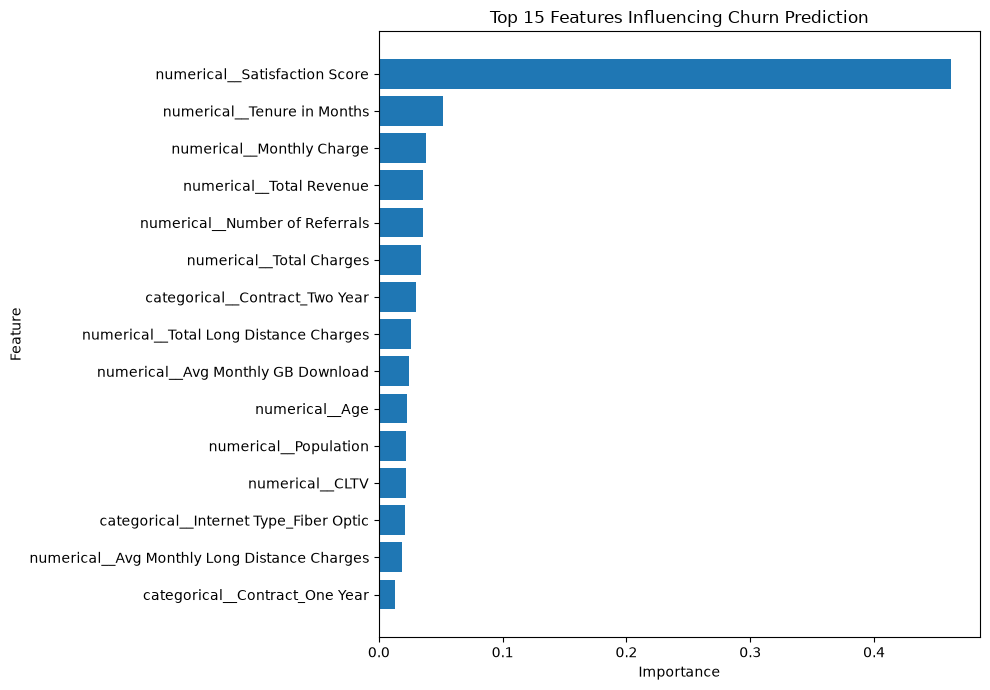

In [49]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features Influencing Churn Prediction")

plt.tight_layout()
plt.show()

In [50]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt

# Run permutation importance
perm_importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="accuracy",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create DataFrame
perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_importance.importances_mean
})

# Sort by importance
perm_df = perm_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top features
print(perm_df.head(15))

                        Feature  Importance
35           Satisfaction Score    0.282257
26                     Contract    0.008730
9           Number of Referrals    0.004826
18              Online Security    0.004116
29               Monthly Charge    0.003336
1                           Age    0.003123
16                Internet Type    0.003052
3                Senior Citizen    0.002697
34                Total Revenue    0.002626
10             Tenure in Months    0.002626
30                Total Charges    0.002413
28               Payment Method    0.001703
8             Referred a Friend    0.001561
17      Avg Monthly GB Download    0.001490
33  Total Long Distance Charges    0.001207


## Version 2 ##

In [51]:
X_v2 = X.drop(columns=["Satisfaction Score"])

In [52]:
print(X_v2.shape)
print(X_v2.columns.tolist())

(7043, 36)
['Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Number of Dependents', 'Population', 'Referred a Friend', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'CLTV']


In [53]:
from sklearn.model_selection import train_test_split

X_train_v2, X_test_v2, y_train_v2, y_test_v2 = train_test_split(
    X_v2,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

categorical_features_v2 = X_v2.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features_v2 = X_v2.select_dtypes(
    exclude=["object"]
).columns.tolist()

preprocessor_v2 = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features_v2
        ),
        (
            "numerical",
            "passthrough",
            numerical_features_v2
        )
    ]
)

C:\Users\bhave\AppData\Local\Temp\ipykernel_4392\1933520622.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_v2 = X_v2.select_dtypes(


In [55]:
rf_model_v2 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_v2),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

In [56]:
rf_model_v2.fit(
    X_train_v2,
    y_train_v2
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](36,)","['Gender','Age','Under 30',...,'Total Long Distance Charges', 'Total Revenue','CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,36
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

In [57]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

y_pred_v2 = rf_model_v2.predict(X_test_v2)

print("Accuracy:", accuracy_score(y_test_v2, y_pred_v2))

print("\nClassification Report:")
print(classification_report(y_test_v2, y_pred_v2))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, y_pred_v2))

Accuracy: 0.8481192334989354

Classification Report:
              precision    recall  f1-score   support

          No       0.87      0.94      0.90      1035
         Yes       0.77      0.61      0.68       374

    accuracy                           0.85      1409
   macro avg       0.82      0.77      0.79      1409
weighted avg       0.84      0.85      0.84      1409


Confusion Matrix:
[[968  67]
 [147 227]]


In [58]:
from sklearn.metrics import roc_auc_score

y_probability_v2 = rf_model_v2.predict_proba(X_test_v2)[:, 1]

roc_auc_v2 = roc_auc_score(
    y_test_v2,
    y_probability_v2
)

print("ROC-AUC:", roc_auc_v2)

ROC-AUC: 0.8956780076984681


In [59]:
print(rf_model_v2.named_steps["classifier"].classes_)

['No' 'Yes']


In [60]:
rf_classifier_v2 = rf_model_v2.named_steps["classifier"]

importance_v2 = rf_classifier_v2.feature_importances_

preprocessor_v2_fitted = rf_model_v2.named_steps["preprocessor"]

feature_names_v2 = preprocessor_v2_fitted.get_feature_names_out()

feature_importance_v2 = pd.DataFrame({
    "Feature": feature_names_v2,
    "Importance": importance_v2
})

feature_importance_v2 = feature_importance_v2.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_v2.head(20)

,Feature,Importance
34,numerical__Tenure in Months,0.074624
37,numerical__Monthly Charge,0.073324
38,numerical__Total Charges,0.070860
42,numerical__Total Revenue,0.069158
33,numerical__Number of Referrals,0.054924
41,numerical__Total Long Distance Charges,0.052158
26,categorical__Contract_Two Year,0.051718
43,numerical__CLTV,0.050191
30,numerical__Age,0.050126
32,numerical__Population,0.049073


## Version 3 ##

In [61]:
X_v3 = X.drop(columns=[
    "Population",
    "Number of Referrals",
    "Avg Monthly Long Distance Charges",
    "Avg Monthly GB Download",
    "Total Charges",
    "Total Refunds",
    "Total Extra Data Charges",
    "Total Long Distance Charges",
    "Total Revenue",
    "CLTV",
    "Satisfaction Score"
])

print(X_v3.shape)
print(X_v3.columns.tolist())

(7043, 26)
['Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Number of Dependents', 'Referred a Friend', 'Tenure in Months', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge']


In [62]:
from sklearn.model_selection import train_test_split

X_train_v3, X_test_v3, y_train_v3, y_test_v3 = train_test_split(
    X_v3,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [63]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

categorical_features_v3 = X_v3.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features_v3 = X_v3.select_dtypes(
    exclude=["object"]
).columns.tolist()

preprocessor_v3 = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features_v3
        ),
        (
            "numerical",
            "passthrough",
            numerical_features_v3
        )
    ]
)

C:\Users\bhave\AppData\Local\Temp\ipykernel_4392\1641728882.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_v3 = X_v3.select_dtypes(


In [64]:
rf_model_v3 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_v3),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=42
            )
        )
    ]
)

In [65]:
rf_model_v3.fit(
    X_train_v3,
    y_train_v3
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](26,)","['Gender','Age','Under 30',...,'Paperless Billing','Payment Method', 'Monthly Charge']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,26
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By sp

In [66]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

y_pred_v3 = rf_model_v3.predict(X_test_v3)

print("Accuracy:", accuracy_score(y_test_v3, y_pred_v3))

print("\nClassification Report:")
print(classification_report(y_test_v3, y_pred_v3))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v3, y_pred_v3))

y_probability_v3 = rf_model_v3.predict_proba(X_test_v3)[:, 1]

print(
    "\nROC-AUC:",
    roc_auc_score(
        y_test_v3,
        y_probability_v3
    )
)

Accuracy: 0.8239886444286728

Classification Report:
              precision    recall  f1-score   support

          No       0.85      0.92      0.88      1035
         Yes       0.71      0.56      0.63       374

    accuracy                           0.82      1409
   macro avg       0.78      0.74      0.76      1409
weighted avg       0.82      0.82      0.82      1409


Confusion Matrix:
[[951  84]
 [164 210]]

ROC-AUC: 0.8738342504327159


## V4 STEP 1: Create the V4 dataset ##

In [67]:
# ============================================
# V4 - Feature Selection
# ============================================

X_v4 = X.drop(
    columns=[
        "Satisfaction Score",
        "Population",
        "CLTV"
    ]
)

print("V4 Shape:", X_v4.shape)
print("\nV4 Features:")
print(X_v4.columns.tolist())

V4 Shape: (7043, 34)

V4 Features:
['Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Number of Dependents', 'Referred a Friend', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']


## V4 STEP 2: Train/test split ##

In [68]:
from sklearn.model_selection import train_test_split

X_train_v4, X_test_v4, y_train_v4, y_test_v4 = train_test_split(
    X_v4,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train_v4.shape)
print("Testing set:", X_test_v4.shape)

Training set: (5634, 34)
Testing set: (1409, 34)


## V4 STEP 3: Identify categorical and numerical features ##

In [69]:
categorical_features_v4 = X_v4.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features_v4 = X_v4.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical features:", len(categorical_features_v4))
print("Numerical features:", len(numerical_features_v4))

print("\nCategorical:")
print(categorical_features_v4)

print("\nNumerical:")
print(numerical_features_v4)

Categorical features: 22
Numerical features: 12

Categorical:
['Gender', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Referred a Friend', 'Offer', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method']

Numerical:
['Age', 'Number of Dependents', 'Number of Referrals', 'Tenure in Months', 'Avg Monthly Long Distance Charges', 'Avg Monthly GB Download', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue']


C:\Users\bhave\AppData\Local\Temp\ipykernel_4392\3156869425.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features_v4 = X_v4.select_dtypes(


## V4 STEP 4: Build the preprocessor ##

In [70]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor_v4 = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features_v4
        ),
        (
            "numerical",
            "passthrough",
            numerical_features_v4
        )
    ]
)

## V4 STEP 5: Build the improved Random Forest ##

In [71]:
from sklearn.ensemble import RandomForestClassifier

rf_model_v4 = Pipeline(
    steps=[
        ("preprocessor", preprocessor_v4),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced",
                n_jobs=-1
            )
        )
    ]
)

## V4 STEP 6: Train ##

In [72]:
rf_model_v4.fit(
    X_train_v4,
    y_train_v4
)

print("V4 model training completed successfully.")

V4 model training completed successfully.


## V4 STEP 7: Standard evaluation ##

In [73]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# Predictions
y_pred_v4 = rf_model_v4.predict(X_test_v4)

# Probabilities
y_probability_v4 = rf_model_v4.predict_proba(X_test_v4)[:, 1]

# Accuracy
accuracy_v4 = accuracy_score(
    y_test_v4,
    y_pred_v4
)

print("Accuracy:", accuracy_v4)

print("\nClassification Report:")
print(
    classification_report(
        y_test_v4,
        y_pred_v4
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_v4,
        y_pred_v4
    )
)

roc_auc_v4 = roc_auc_score(
    y_test_v4,
    y_probability_v4
)

print("\nROC-AUC:", roc_auc_v4)

Accuracy: 0.843860894251242

Classification Report:
              precision    recall  f1-score   support

          No       0.91      0.88      0.89      1035
         Yes       0.69      0.75      0.72       374

    accuracy                           0.84      1409
   macro avg       0.80      0.81      0.81      1409
weighted avg       0.85      0.84      0.85      1409


Confusion Matrix:
[[908 127]
 [ 93 281]]

ROC-AUC: 0.899966416078948


## V4 STEP 8: Feature importance ##

In [74]:
rf_classifier_v4 = rf_model_v4.named_steps["classifier"]

importance_v4 = rf_classifier_v4.feature_importances_

preprocessor_v4_fitted = (
    rf_model_v4.named_steps["preprocessor"]
)

feature_names_v4 = (
    preprocessor_v4_fitted
    .get_feature_names_out()
)

feature_importance_v4 = pd.DataFrame({
    "Feature": feature_names_v4,
    "Importance": importance_v4
})

feature_importance_v4 = (
    feature_importance_v4
    .sort_values(
        by="Importance",
        ascending=False
    )
)

feature_importance_v4.head(20)

,Feature,Importance
33,numerical__Tenure in Months,0.080070
32,numerical__Number of Referrals,0.079994
26,categorical__Contract_Two Year,0.079481
36,numerical__Monthly Charge,0.073779
41,numerical__Total Revenue,0.073312
37,numerical__Total Charges,0.068149
40,numerical__Total Long Distance Charges,0.058228
30,numerical__Age,0.050244
35,numerical__Avg Monthly GB Download,0.050131
34,numerical__Avg Monthly Long Distance Charges,0.046313


## V4 STEP 9: Clean feature-importance graph ##

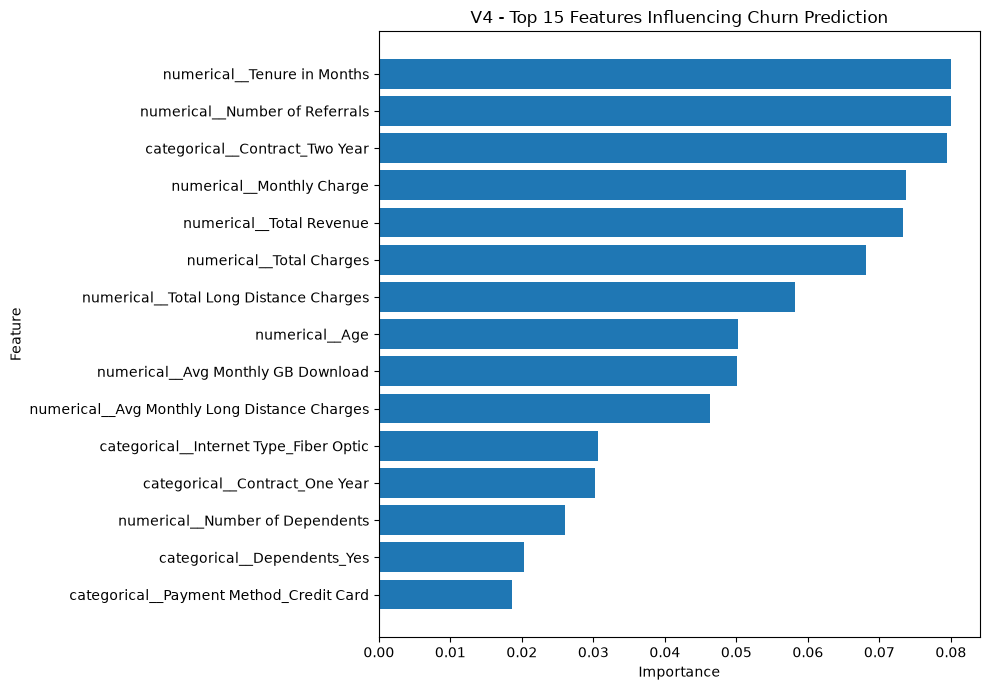

In [75]:
import matplotlib.pyplot as plt

top_features_v4 = feature_importance_v4.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features_v4["Feature"][::-1],
    top_features_v4["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("V4 - Top 15 Features Influencing Churn Prediction")

plt.tight_layout()
plt.show()

## 🧪 V4 STEP 10: The interesting part, threshold analysis ##
Model currently essentially uses:
Probability >= 0.50 → Churn
Probability < 0.50 → Stay
But imagine:
Customer A → 48% churn probability
The model says:
Stay
But for a telecom company, perhaps you'd rather say:
"48% is high enough to contact this customer."
So let's test multiple thresholds

In [76]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results_v4 = []

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

    y_pred_threshold = (
        y_probability_v4 >= threshold
    ).astype(int)

    # Convert 0/1 predictions back to No/Yes
    y_pred_threshold = pd.Series(
        y_pred_threshold,
        index=y_test_v4.index
    ).map({
        0: "No",
        1: "Yes"
    })

    precision = precision_score(
        y_test_v4,
        y_pred_threshold,
        pos_label="Yes"
    )

    recall = recall_score(
        y_test_v4,
        y_pred_threshold,
        pos_label="Yes"
    )

    f1 = f1_score(
        y_test_v4,
        y_pred_threshold,
        pos_label="Yes"
    )

    threshold_results_v4.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

threshold_df_v4 = pd.DataFrame(
    threshold_results_v4
)

threshold_df_v4

,Threshold,Precision,Recall,F1 Score
0,0.30,0.539185,0.919786,0.679842
1,0.35,0.569930,0.871658,0.689218
2,0.40,0.622530,0.842246,0.715909
3,0.45,0.652747,0.794118,0.716526
4,0.50,0.687042,0.751337,0.717752
5,0.55,0.702997,0.689840,0.696356
6,0.60,0.733974,0.612299,0.667638


In [77]:
import os
import joblib

model_dir = r"D:\Documents\Portfolio Projects\IntelliChurn\App\Models"

os.makedirs(model_dir, exist_ok=True)

print("Models folder ready:")
print(model_dir)

Models folder ready:
D:\Documents\Portfolio Projects\IntelliChurn\App\Models


In [78]:
model_path = os.path.join(
    model_dir,
    "intellichurn_v4.pkl"
)

joblib.dump(rf_model_v2, model_path)

print("V4 model saved successfully!")
print(model_path)

V4 model saved successfully!
D:\Documents\Portfolio Projects\IntelliChurn\App\Models\intellichurn_v4.pkl


In [79]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully!")
print(loaded_model)

Model loaded successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Under 30',
                                                   'Senior Citizen', 'Married',
                                                   'Dependents',
                                                   'Referred a Friend', 'Offer',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Internet Type',
                                                   'Online Security',
                                                   'Online Bac

In [80]:
original_predictions = rf_model_v2.predict(X_test_v2)
loaded_predictions = loaded_model.predict(X_test_v2)

print(
    "Predictions identical:",
    (original_predictions == loaded_predictions).all()
)

Predictions identical: True


In [81]:
original_probabilities = rf_model_v2.predict_proba(X_test_v2)
loaded_probabilities = loaded_model.predict_proba(X_test_v2)

print(
    "Probabilities identical:",
    (original_probabilities == loaded_probabilities).all()
)

Probabilities identical: True


In [82]:
threshold = 0.45

threshold_path = os.path.join(
    model_dir,
    "threshold.txt"
)

with open(threshold_path, "w") as f:
    f.write(str(threshold))

print("Threshold saved successfully!")
print("Threshold:", threshold)
print(threshold_path)

Threshold saved successfully!
Threshold: 0.45
D:\Documents\Portfolio Projects\IntelliChurn\App\Models\threshold.txt


In [83]:
churn_probability = rf_model_v2.predict_proba(X_test_v2)[:, 1]

threshold = 0.45

v4_predictions = np.where(
    churn_probability >= threshold,
    "Yes",
    "No"
)

print("V4 predictions using threshold 0.45:")
print(pd.Series(v4_predictions).value_counts())

V4 predictions using threshold 0.45:
No     1069
Yes     340
Name: count, dtype: int64


In [84]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Accuracy:")
print(accuracy_score(y_test_v2, v4_predictions))

print("\nClassification Report:")
print(classification_report(y_test_v2, v4_predictions))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_v2, v4_predictions))

print("\nROC-AUC:")
print(roc_auc_score(
    (y_test_v2 == "Yes").astype(int),
    churn_probability
))

Accuracy:
0.8481192334989354

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.91      0.90      1035
         Yes       0.74      0.67      0.70       374

    accuracy                           0.85      1409
   macro avg       0.81      0.79      0.80      1409
weighted avg       0.84      0.85      0.85      1409


Confusion Matrix:
[[945  90]
 [124 250]]

ROC-AUC:
0.8956780076984681


In [85]:
print("rf_model_v2 object:")
print(rf_model_v2)

print("\nPipeline steps:")
print(rf_model_v2.named_steps)

print("\nClassifier:")
print(rf_model_v2.named_steps["classifier"])

print("\nNumber of input features:")
print(len(rf_model_v2.feature_names_in_))

print("\nInput features:")
print(rf_model_v2.feature_names_in_.tolist())

rf_model_v2 object:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Under 30',
                                                   'Senior Citizen', 'Married',
                                                   'Dependents',
                                                   'Referred a Friend', 'Offer',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Internet Type',
                                                   'Online Security',
                                                   'Online Backup',
 

In [86]:
print("Satisfaction Score" in rf_model_v2.feature_names_in_)

False


In [87]:
print("X_v2 shape:", X_v2.shape)
print("Model input features:", len(rf_model_v2.feature_names_in_))

X_v2 shape: (7043, 36)
Model input features: 36


In [88]:
print(rf_model_v2.feature_names_in_.tolist())

['Gender', 'Age', 'Under 30', 'Senior Citizen', 'Married', 'Dependents', 'Number of Dependents', 'Population', 'Referred a Friend', 'Number of Referrals', 'Tenure in Months', 'Offer', 'Phone Service', 'Avg Monthly Long Distance Charges', 'Multiple Lines', 'Internet Service', 'Internet Type', 'Avg Monthly GB Download', 'Online Security', 'Online Backup', 'Device Protection Plan', 'Premium Tech Support', 'Streaming TV', 'Streaming Movies', 'Streaming Music', 'Unlimited Data', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charge', 'Total Charges', 'Total Refunds', 'Total Extra Data Charges', 'Total Long Distance Charges', 'Total Revenue', 'CLTV']


In [89]:
from sklearn.metrics import roc_auc_score

v4_probability_check = rf_model_v2.predict_proba(X_test_v2)[:, 1]

print(
    "ROC-AUC:",
    roc_auc_score(
        (y_test_v2 == "Yes").astype(int),
        v4_probability_check
    )
)

ROC-AUC: 0.8956780076984681


In [90]:
print("===== CURRENT V4 MODEL =====")

print("\nModel type:")
print(type(rf_model_v2))

print("\nInput feature count:")
print(len(rf_model_v2.feature_names_in_))

print("\nSatisfaction Score present?")
print("Satisfaction Score" in rf_model_v2.feature_names_in_)

print("\nX_test_v2 shape:")
print(X_test_v2.shape)

print("\ny_test_v2 shape:")
print(y_test_v2.shape)

print("\nX_test_v2 index range:")
print(X_test_v2.index.min(), "to", X_test_v2.index.max())

print("\nFirst 10 test indices:")
print(X_test_v2.index[:10].tolist())

print("\nClassifier:")
print(rf_model_v2.named_steps["classifier"])

print("\n===== CURRENT MODEL AUC =====")

from sklearn.metrics import roc_auc_score

current_probability = rf_model_v2.predict_proba(X_test_v2)[:, 1]

current_auc = roc_auc_score(
    (y_test_v2 == "Yes").astype(int),
    current_probability
)

print("Current ROC-AUC:", current_auc)

===== CURRENT V4 MODEL =====

Model type:
<class 'sklearn.pipeline.Pipeline'>

Input feature count:
36

Satisfaction Score present?
False

X_test_v2 shape:
(1409, 36)

y_test_v2 shape:
(1409,)

X_test_v2 index range:
5 to 7037

First 10 test indices:
[803, 3549, 3515, 5162, 4642, 6096, 4504, 4067, 6233, 430]

Classifier:
RandomForestClassifier(n_estimators=200, random_state=42)

===== CURRENT MODEL AUC =====
Current ROC-AUC: 0.8956780076984681


In [91]:
# ============================================
# V4 TRAINING / TEST SPLIT VERIFICATION
# ============================================

print("===== DATASET SPLIT =====")

print("X_v2 shape:", X_v2.shape)
print("y shape:", y.shape)

print("\nX_train_v2 shape:", X_train_v2.shape)
print("X_test_v2 shape:", X_test_v2.shape)

print("\ny_train_v2 shape:", y_train_v2.shape)
print("y_test_v2 shape:", y_test_v2.shape)

print("\nTraining index range:")
print(X_train_v2.index.min(), "to", X_train_v2.index.max())

print("\nTesting index range:")
print(X_test_v2.index.min(), "to", X_test_v2.index.max())

print("\nFirst 20 training indices:")
print(X_train_v2.index[:20].tolist())

print("\nFirst 20 testing indices:")
print(X_test_v2.index[:20].tolist())

print("\n===== TARGET DISTRIBUTION =====")

print("\nTraining:")
print(y_train_v2.value_counts())

print("\nTesting:")
print(y_test_v2.value_counts())

print("\n===== MODEL FEATURE COUNT =====")

print(
    "Model features:",
    len(rf_model_v2.feature_names_in_)
)

print(
    "X_train features:",
    X_train_v2.shape[1]
)

print(
    "X_test features:",
    X_test_v2.shape[1]
)

print("\n===== MODEL FIT CHECK =====")

print(
    "Satisfaction Score in model:",
    "Satisfaction Score" in rf_model_v2.feature_names_in_
)

print(
    "Random Forest:",
    rf_model_v2.named_steps["classifier"]
)

===== DATASET SPLIT =====
X_v2 shape: (7043, 36)
y shape: (7043,)

X_train_v2 shape: (5634, 36)
X_test_v2 shape: (1409, 36)

y_train_v2 shape: (5634,)
y_test_v2 shape: (1409,)

Training index range:
0 to 7042

Testing index range:
5 to 7037

First 20 training indices:
[4626, 4192, 5457, 4717, 4673, 3840, 3823, 617, 6112, 3535, 3822, 6978, 4769, 3911, 4166, 4077, 5873, 720, 483, 5228]

First 20 testing indices:
[803, 3549, 3515, 5162, 4642, 6096, 4504, 4067, 6233, 430, 3396, 2815, 975, 1583, 5769, 838, 6375, 3437, 6655, 5822]

===== TARGET DISTRIBUTION =====

Training:
Churn Label
No     4139
Yes    1495
Name: count, dtype: int64

Testing:
Churn Label
No     1035
Yes     374
Name: count, dtype: int64

===== MODEL FEATURE COUNT =====
Model features: 36
X_train features: 36
X_test features: 36

===== MODEL FIT CHECK =====
Satisfaction Score in model: False
Random Forest: RandomForestClassifier(n_estimators=200, random_state=42)


In [92]:
# ============================================
# RE-FIT A CLEAN V4 MODEL
# ============================================

from sklearn.base import clone
from sklearn.metrics import roc_auc_score

rf_model_v4_check = clone(rf_model_v2)

rf_model_v4_check.fit(
    X_train_v2,
    y_train_v2
)

v4_check_probability = rf_model_v4_check.predict_proba(
    X_test_v2
)[:, 1]

v4_check_auc = roc_auc_score(
    (y_test_v2 == "Yes").astype(int),
    v4_check_probability
)

print("Clean V4 re-fit ROC-AUC:", v4_check_auc)

Clean V4 re-fit ROC-AUC: 0.8956780076984681


In [93]:
import os
import joblib

model_dir = r"D:\Documents\Portfolio Projects\IntelliChurn\App\Models"

os.makedirs(model_dir, exist_ok=True)

v4_model_path = os.path.join(
    model_dir,
    "intellichurn_v4.pkl"
)

joblib.dump(
    rf_model_v2,
    v4_model_path
)

print("✅ IntelliChurn V4 saved!")
print(v4_model_path)

✅ IntelliChurn V4 saved!
D:\Documents\Portfolio Projects\IntelliChurn\App\Models\intellichurn_v4.pkl


In [94]:
v4_threshold = 0.45

threshold_path = os.path.join(
    model_dir,
    "threshold.txt"
)

with open(threshold_path, "w") as f:
    f.write(str(v4_threshold))

print("✅ V4 threshold saved!")
print("Threshold:", v4_threshold)
print(threshold_path)

✅ V4 threshold saved!
Threshold: 0.45
D:\Documents\Portfolio Projects\IntelliChurn\App\Models\threshold.txt


In [95]:
loaded_v4 = joblib.load(v4_model_path)

print("Loaded model successfully!")
print(loaded_v4)

Loaded model successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['Gender', 'Under 30',
                                                   'Senior Citizen', 'Married',
                                                   'Dependents',
                                                   'Referred a Friend', 'Offer',
                                                   'Phone Service',
                                                   'Multiple Lines',
                                                   'Internet Service',
                                                   'Internet Type',
                                                   'Online Security',
                                                   'Online Bac

In [96]:
import numpy as np

original_prob = rf_model_v2.predict_proba(X_test_v2)
loaded_prob = loaded_v4.predict_proba(X_test_v2)

print(
    "Probabilities identical:",
    np.allclose(original_prob, loaded_prob)
)

Probabilities identical: True


In [97]:
original_pred = rf_model_v2.predict(X_test_v2)
loaded_pred = loaded_v4.predict(X_test_v2)

print(
    "Predictions identical:",
    np.array_equal(original_pred, loaded_pred)
)

Predictions identical: True


In [98]:
probabilities = loaded_v4.predict_proba(X_test_v2)[:, 1]

application_predictions = np.where(
    probabilities >= 0.45,
    "Yes",
    "No"
)

print("Predictions using threshold 0.45:")
print(pd.Series(application_predictions).value_counts())

Predictions using threshold 0.45:
No     1069
Yes     340
Name: count, dtype: int64


In [99]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:")
print(
    accuracy_score(
        y_test_v2,
        application_predictions
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test_v2,
        application_predictions
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_v2,
        application_predictions
    )
)

Accuracy:
0.8481192334989354

Classification Report:
              precision    recall  f1-score   support

          No       0.88      0.91      0.90      1035
         Yes       0.74      0.67      0.70       374

    accuracy                           0.85      1409
   macro avg       0.81      0.79      0.80      1409
weighted avg       0.84      0.85      0.85      1409


Confusion Matrix:
[[945  90]
 [124 250]]


### Version 5 Setup ###

In [102]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# ============================================================
# V5 - CLEAN FEATURE SET
# ============================================================

# IMPORTANT:
# V5 uses the exact same 36 features as V4.
# Satisfaction Score is intentionally NOT included.

print("V5 input shape:", X_train_v2.shape)
print("Satisfaction Score present?",
      "Satisfaction Score" in X_train_v2.columns)


# ============================================================
# Identify columns
# ============================================================

categorical_features = X_train_v2.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X_train_v2.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()


print("\nCategorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total features:", len(categorical_features) + len(numerical_features))


# ============================================================
# Preprocessing
# ============================================================

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        drop="first",
        handle_unknown="ignore"
    ))
])

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])


preprocessor_v5 = ColumnTransformer([
    ("categorical", categorical_pipeline, categorical_features),
    ("numerical", numerical_pipeline, numerical_features)
])


# ============================================================
# V5 Random Forest
# ============================================================

rf_v5 = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=4,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)


# ============================================================
# Complete Pipeline
# ============================================================

rf_model_v5 = Pipeline([
    ("preprocessor", preprocessor_v5),
    ("classifier", rf_v5)
])


# ============================================================
# Train
# ============================================================

rf_model_v5.fit(
    X_train_v2,
    y_train_v2
)


# ============================================================
# Predictions
# ============================================================

y_pred_v5 = rf_model_v5.predict(X_test_v2)

y_prob_v5 = rf_model_v5.predict_proba(
    X_test_v2
)[:, 1]


# ============================================================
# Evaluation
# ============================================================

accuracy_v5 = accuracy_score(
    y_test_v2,
    y_pred_v5
)

auc_v5 = roc_auc_score(
    y_test_v2,
    y_prob_v5
)


print("\n================ V5 RESULTS ================\n")

print("Accuracy:")
print(accuracy_v5)

print("\nClassification Report:")
print(classification_report(
    y_test_v2,
    y_pred_v5
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test_v2,
    y_pred_v5
))

print("\nROC-AUC:")
print(auc_v5)

V5 input shape: (5634, 36)
Satisfaction Score present? False

Categorical features: 22
Numerical features: 14
Total features: 36

================ V5 RESULTS ================

Accuracy:
0.8282469836763662

Classification Report:
              precision    recall  f1-score   support

          No       0.93      0.83      0.88      1035
         Yes       0.64      0.83      0.72       374

    accuracy                           0.83      1409
   macro avg       0.78      0.83      0.80      1409
weighted avg       0.85      0.83      0.83      1409

Confusion Matrix:
[[858 177]
 [ 65 309]]

ROC-AUC:
0.9030871373582371


In [103]:
# ============================================================
# V5 OVERFITTING CHECK
# ============================================================

from sklearn.metrics import roc_auc_score, accuracy_score

# Training predictions
y_train_pred_v5 = rf_model_v5.predict(X_train_v2)
y_train_prob_v5 = rf_model_v5.predict_proba(X_train_v2)[:, 1]

# Testing predictions
y_test_pred_v5 = rf_model_v5.predict(X_test_v2)
y_test_prob_v5 = rf_model_v5.predict_proba(X_test_v2)[:, 1]

# Metrics
train_accuracy_v5 = accuracy_score(y_train_v2, y_train_pred_v5)
test_accuracy_v5 = accuracy_score(y_test_v2, y_test_pred_v5)

train_auc_v5 = roc_auc_score(
    (y_train_v2 == "Yes").astype(int),
    y_train_prob_v5
)

test_auc_v5 = roc_auc_score(
    (y_test_v2 == "Yes").astype(int),
    y_test_prob_v5
)

print("========== V5 OVERFITTING CHECK ==========")

print(f"Training Accuracy : {train_accuracy_v5:.4f}")
print(f"Testing Accuracy  : {test_accuracy_v5:.4f}")

print()

print(f"Training ROC-AUC  : {train_auc_v5:.4f}")
print(f"Testing ROC-AUC   : {test_auc_v5:.4f}")

print()

print(f"Accuracy Gap      : {train_accuracy_v5 - test_accuracy_v5:.4f}")
print(f"ROC-AUC Gap       : {train_auc_v5 - test_auc_v5:.4f}")

========== V5 OVERFITTING CHECK ==========
Training Accuracy : 0.8912
Testing Accuracy  : 0.8282

Training ROC-AUC  : 0.9733
Testing ROC-AUC   : 0.9031

Accuracy Gap      : 0.0629
ROC-AUC Gap       : 0.0703


## Version 6  ##

In [104]:
# ============================================================
# IntelliChurn V6
# Tuned Random Forest - Reduced Overfitting
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

# ============================================================
# SAFETY CHECKS
# ============================================================

print("========== V6 INPUT VALIDATION ==========")

print("X_train_v2 shape:", X_train_v2.shape)
print("X_test_v2 shape :", X_test_v2.shape)

print(
    "Satisfaction Score present?",
    "Satisfaction Score" in X_train_v2.columns
)

print(
    "Train/Test feature count:",
    X_train_v2.shape[1],
    X_test_v2.shape[1]
)

# Stop immediately if the feature setup is wrong
assert X_train_v2.shape[1] == 36
assert X_test_v2.shape[1] == 36
assert "Satisfaction Score" not in X_train_v2.columns
assert "Satisfaction Score" not in X_test_v2.columns

print("✓ V6 input validation passed")


# ============================================================
# IDENTIFY FEATURES
# ============================================================

categorical_features = X_train_v2.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

numerical_features = X_train_v2.select_dtypes(
    include=["number"]
).columns.tolist()

print("\nCategorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print(
    "Total features:",
    len(categorical_features) + len(numerical_features)
)

assert len(categorical_features) + len(numerical_features) == 36

print("✓ Feature selection passed")


# ============================================================
# PREPROCESSING
# ============================================================

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore"
        )
    )
])

numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])


preprocessor_v6 = ColumnTransformer([
    (
        "categorical",
        categorical_pipeline,
        categorical_features
    ),
    (
        "numerical",
        numerical_pipeline,
        numerical_features
    )
])


# ============================================================
# V6 RANDOM FOREST
# ============================================================

rf_v6 = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features="sqrt",
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)


# ============================================================
# COMPLETE V6 PIPELINE
# ============================================================

rf_model_v6 = Pipeline([
    (
        "preprocessor",
        preprocessor_v6
    ),
    (
        "classifier",
        rf_v6
    )
])


# ============================================================
# TRAIN
# ============================================================

rf_model_v6.fit(
    X_train_v2,
    y_train_v2
)

print("\n✓ V6 training completed")


# ============================================================
# PREDICTIONS
# ============================================================

y_pred_v6 = rf_model_v6.predict(X_test_v2)

y_prob_v6 = rf_model_v6.predict_proba(
    X_test_v2
)[:, 1]


# ============================================================
# EVALUATION
# ============================================================

accuracy_v6 = accuracy_score(
    y_test_v2,
    y_pred_v6
)

auc_v6 = roc_auc_score(
    (y_test_v2 == "Yes").astype(int),
    y_prob_v6
)


print("\n")
print("=" * 60)
print("INTELLICHURN V6 RESULTS")
print("=" * 60)

print("\nAccuracy:")
print(accuracy_v6)

print("\nClassification Report:")
print(
    classification_report(
        y_test_v2,
        y_pred_v6
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_v2,
        y_pred_v6
    )
)

print("\nROC-AUC:")
print(auc_v6)

========== V6 INPUT VALIDATION ==========
X_train_v2 shape: (5634, 36)
X_test_v2 shape : (1409, 36)
Satisfaction Score present? False
Train/Test feature count: 36 36
✓ V6 input validation passed

Categorical features: 22
Numerical features: 14
Total features: 36
✓ Feature selection passed

✓ V6 training completed


INTELLICHURN V6 RESULTS

Accuracy:
0.8168914123491838

Classification Report:
              precision    recall  f1-score   support

          No       0.93      0.81      0.87      1035
         Yes       0.61      0.83      0.71       374

    accuracy                           0.82      1409
   macro avg       0.77      0.82      0.79      1409
weighted avg       0.85      0.82      0.82      1409


Confusion Matrix:
[[840 195]
 [ 63 311]]

ROC-AUC:
0.9015293600971351


For IntelliChurn, I care more about correctly identifying customers who are actually going to churn than squeezing out another 1% of accuracy. So the next step should be to tune V5's decision threshold, rather than throwing another model into the blender.

In [105]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

# ============================================================
# V5 THRESHOLD OPTIMIZATION
# ============================================================

# Get churn probabilities
v5_probabilities = rf_model_v5.predict_proba(X_test_v2)[:, 1]

threshold_results = []

for threshold in np.arange(0.30, 0.61, 0.05):

    y_pred_threshold = np.where(
        v5_probabilities >= threshold,
        "Yes",
        "No"
    )

    precision = precision_score(
        y_test_v2,
        y_pred_threshold,
        pos_label="Yes"
    )

    recall = recall_score(
        y_test_v2,
        y_pred_threshold,
        pos_label="Yes"
    )

    f1 = f1_score(
        y_test_v2,
        y_pred_threshold,
        pos_label="Yes"
    )

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1 Score": round(f1, 4)
    })


threshold_df = pd.DataFrame(threshold_results)

print("========== V5 THRESHOLD ANALYSIS ==========")
print(threshold_df)

========== V5 THRESHOLD ANALYSIS ==========
   Threshold  Precision  Recall  F1 Score
0       0.30     0.5021  0.9572    0.6587
1       0.35     0.5364  0.9251    0.6791
2       0.40     0.5607  0.8770    0.6840
3       0.45     0.5966  0.8503    0.7012
4       0.50     0.6358  0.8262    0.7186
5       0.55     0.6629  0.7781    0.7159
6       0.60     0.6865  0.7086    0.6974


In [106]:
best_threshold = threshold_df.loc[
    threshold_df["F1 Score"].idxmax()
]

print("\n========== BEST V5 THRESHOLD ==========")
print(best_threshold)


========== BEST V5 THRESHOLD ==========
Threshold    0.5000
Precision    0.6358
Recall       0.8262
F1 Score     0.7186
Name: 4, dtype: float64


In [107]:
import joblib

MODEL_PATH_V5 = "intellichurn_model_v5.pkl"

joblib.dump(
    rf_model_v5,
    MODEL_PATH_V5
)

print("V5 model saved successfully.")
print(f"Path: {MODEL_PATH_V5}")

V5 model saved successfully.
Path: intellichurn_model_v5.pkl


In [108]:
import joblib

loaded_v5 = joblib.load("intellichurn_model_v5.pkl")

print("Loaded model type:")
print(type(loaded_v5))

print("\nModel input features:")
print(loaded_v5.n_features_in_)

print("\nModel loaded successfully.")

Loaded model type:
<class 'sklearn.pipeline.Pipeline'>

Model input features:
36

Model loaded successfully.


In [109]:
loaded_probabilities = loaded_v5.predict_proba(X_test_v2)[:, 1]

print("Original AUC:",
      roc_auc_score(y_test_v2, v5_probabilities))

print("Loaded AUC:",
      roc_auc_score(y_test_v2, loaded_probabilities))

Original AUC: 0.9030871373582371
Loaded AUC: 0.9030871373582371
